# JointTimeGrad — Paper Figures (NeurIPS)

Generates the headline table and four main-paper figures, plus the appendix
table and three appendix figures, as specified in
`docs/internal/PAPER_FIGURES_PLAN.md`.

**Models compared (6 columns):** JointTimeGrad, TimeGrad-Q (queue-only ablation),
TimeGrad-R (return-only ablation), CGAN, Hawkes, Poisson.

**Outputs land in:** `paper_figs/` (PDFs) plus inline LaTeX cells for the tables.

To skip a model that isn't checkpointed yet (e.g. TimeGrad-Q while training
is still running on the server), the notebook will warn and continue with the
remaining columns.


In [1]:
%reload_ext autoreload
%autoreload 2

## §0  Configuration


In [9]:
# ─── Canonical paper checkpoints (curated copies under checkpoints/final/) ──
# Naming map (paper ↔ checkpoint):
#   LOBGrad     ← final/joint_timegrad             (headline: joint baseline)
#   LG-Q, LG-R  ← queue-only / return-only ablations
#   LG-NE       ← timegrad_joint_flat_window       (no-encoder, flat-window cond)
TG_CKPT       = "checkpoints/final/joint_timegrad/best_model.pt"              # ← headline (LOBGrad)
TGQ_CKPT      = "checkpoints/final/timegrad_queue_only/best_model.pt"               # queue-only
TGR_CKPT      = "checkpoints/final/timegrad_return_only/best_model.pt"              # return-only
TGNW_CKPT     = "checkpoints/final/timegrad_joint_flat_window/final_model.pt"        # no-encoder, flat-window
CGAN_CKPT     = "checkpoints/final/cgan/cgan.pt"

TG_LABEL       = "LOBGrad"      # headline (joint baseline)
TGQ_LABEL      = "LG-Q"
TGR_LABEL      = "LG-R"
TGNW_LABEL     = "LG-NE"

# ─── Architecture (frozen — matches the trial_88 final model) ───────────────
K              = 5         # LOB levels per side  → 2K queue features
PRICE_LEVEL    = 2.0       # tick size δ in USDT
CONTEXT_LEN    = 100       # conditioning window length (snapshots)
HORIZON        = 20        # generation horizon (matches scripts/paper_figures_v2_server.py)
N_PATHS        = 100        # generated paths per window
N_WINDOWS      = 500       # test windows for distributional metrics
N_EXEC_WIN     = 500       # windows for the execution experiment

EMB_DIM        = 32
HIDDEN_ENC     = 151
HIDDEN_NOISE   = 255
DIFFUSION_K    = 102
NUM_ENC_LAYERS = 1
CELL_TYPE      = "LSTM"
USE_COND_PROJ  = True
LOSS_TYPE      = "l2"

# CGAN trial_42 hyperparameters (from scripts/paper_figures_v2_server.py)
CGAN_HP = dict(
    queue_mode       = "absolute",
    latent_dim       = 74,
    hidden_dim       = 367,
    n_encoder_layers = 1,
    n_decoder_layers = 2,
)

# Output dirs (split into main paper / appendix / tables)
SAVE_FIGS    = True
MAIN_DIR     = "figures/main"
APPENDIX_DIR = "figures/appendix"
TABLE_DIR    = "figures/tables"


## §1  Setup — imports, plot style, palette


In [10]:
import os, sys
from pathlib import Path

# Find repo root (lobgrad/__init__.py) — handles flat or nested layout
_here = Path.cwd().resolve()
for _p in [_here, *_here.parents]:
    if (_p / "lobgrad" / "__init__.py").is_file():
        REPO_ROOT = _p
        break
else:
    raise RuntimeError("Could not find lobgrad package")

os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print(f"Working from {REPO_ROOT}")


Working from /path/to/repo


In [11]:
%load_ext autoreload
%autoreload 2

import numpy as np
import torch
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **kw: x

# ─── Publication style ───────────────────────────────────────────────
plt.rcParams.update({
    "font.family":          "serif",
    "font.size":            10,
    "axes.labelsize":       10,
    "axes.titlesize":       10,
    "legend.fontsize":      8,
    "xtick.labelsize":      8,
    "ytick.labelsize":      8,
    "axes.spines.top":      False,
    "axes.spines.right":    False,
    "axes.grid":            True,
    "grid.alpha":           0.25,
    "grid.linestyle":       ":",
    "figure.dpi":           120,
    "savefig.dpi":          300,
    "savefig.bbox":         "tight",
    "savefig.pad_inches":   0.02,
})

# ─── Colour palette (used everywhere) ────────────────────────────────
PALETTE = {
    "Real":       "#000000",
    TG_LABEL:     "#0173B2",   # blue
    TGQ_LABEL:    "#56B4E9",   # light blue
    TGR_LABEL:    "#ECE133",   # yellow (return-only ablation)
    TGNW_LABEL:   "#7F7F7F",   # darker gray (no-encoder, flat window)
    "CGAN":       "#CC78BC",   # purple
    "Hawkes":     "#DE8F05",   # orange
    "Poisson":    "#029E73",   # teal
}
LINESTYLES = {
    "Real": "-",
    TG_LABEL: "-",
    TGQ_LABEL: "--",
    TGR_LABEL: "--",
    TGNW_LABEL: "-.",
    "CGAN": "--",
    "Hawkes": ":",
    "Poisson": ":",
}

for _d in (MAIN_DIR, APPENDIX_DIR, TABLE_DIR):
    os.makedirs(_d, exist_ok=True)


def _savefig(fig, name, section="main"):
    """Save into figures/main or figures/appendix based on `section`."""
    if SAVE_FIGS:
        base = MAIN_DIR if section == "main" else APPENDIX_DIR
        path = os.path.join(base, name)
        fig.savefig(path)
        print(f"saved {path}")
    plt.show()


print("Setup complete.")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setup complete.


## §2  Data + Models


In [12]:
from lobgrad.config import BenchmarkConfig
from lobgrad.data.splits import date_splits_joint, sample_eval_windows_joint

# ─── Frozen architecture (matches checkpoints/final/joint_timegrad) ──
cfg = BenchmarkConfig(
    levels                       = K,
    price_level                  = PRICE_LEVEL,
    queue_repr                   = "signed",
    queue_mode                   = "absolute",
    timegrad_checkpoint          = TG_CKPT,
    timegrad_train               = False,
    timegrad_k                   = DIFFUSION_K,
    timegrad_hidden_enc          = HIDDEN_ENC,
    timegrad_hidden_noise        = HIDDEN_NOISE,
    timegrad_num_enc_layers      = NUM_ENC_LAYERS,
    timegrad_emb_dim             = EMB_DIM,
    timegrad_cell_type           = CELL_TYPE,
    timegrad_use_cond_projection = USE_COND_PROJ,
    timegrad_loss_type           = LOSS_TYPE,
    timegrad_schedule            = "linear",
    timegrad_beta_start          = 0.0001,
    timegrad_beta_end            = 0.1,
)

# ─── Load splits ─────────────────────────────────────────────────────
(ts_train, X_train, anchors_train), \
(ts_val,   X_val,   anchors_val),   \
(ts_test,  X_test,  anchors_test),  \
normalizer = date_splits_joint(cfg)

print(f"Train  : {len(X_train):>7,d} snapshots")
print(f"Val    : {len(X_val):>7,d} snapshots")
print(f"Test   : {len(X_test):>7,d} snapshots")
print(f"Queue  : {X_test.shape},  anchors {anchors_test.shape}")

# ─── Sample evaluation windows ───────────────────────────────────────
rng = np.random.default_rng(42)

test_ctx_q, test_fut_q, test_ctx_a, test_fut_a = sample_eval_windows_joint(
    X_test, anchors_test, CONTEXT_LEN, HORIZON, N_WINDOWS, rng=rng
)
print(f"\nWindows  ctx={test_ctx_q.shape}  fut={test_fut_q.shape}")


Train  : 223,378 snapshots
Val    :  28,530 snapshots
Test   :  56,918 snapshots
Queue  : (56918, 10),  anchors (56918,)

Windows  ctx=(500, 100, 10)  fut=(500, 20, 10)


In [13]:
from lobgrad.execution.simulate import JointTimeGradGenerator
from lobgrad.models.timegrad   import TimeGradGenerator
from lobgrad.models.cgan       import CGANGenerator
from lobgrad.models.hawkes     import HawkesGenerator
from lobgrad.models.poisson    import PoissonGenerator

# TimeGradMLP lives in the legacy src/ tree — needed to build the
# return-only (Δmid → mid) ablation generator inline below.
import sys as _sys
_SRC = str(REPO_ROOT / "src")
if _SRC not in _sys.path:
    _sys.path.insert(0, _SRC)
from model import TimeGradMLP  # type: ignore


class ReturnOnlyTimeGradGenerator:
    """Wraps the return-only TimeGrad checkpoint (input/output dim = 1, Δmid).

    Produces only mid-price trajectories — there is no queue head. Used as
    the price-side counterpart to TimeGrad-Q in the headline-table ablation.

    .generate(context_anchors, steps, n_paths) → mid_paths, shape (n_paths, steps).
    """

    def __init__(self, ckpt_path: str, delta_mid_clip: float = 12.0,
                 device: str | None = None):
        self.ckpt_path      = ckpt_path
        self.delta_mid_clip = float(delta_mid_clip)
        self.device         = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model          = TimeGradMLP(
            input_dim           = 1,
            output_dim          = 1,
            hidden_encoder_dim  = HIDDEN_ENC,
            hidden_noise_dim    = HIDDEN_NOISE,
            num_encoder_layers  = NUM_ENC_LAYERS,
            emb_dim             = EMB_DIM,
            K                   = DIFFUSION_K,
            beta_start          = 0.0001,
            beta_end            = 0.1,
            schedule            = "linear",
            cell_type           = CELL_TYPE,
            use_cond_projection = USE_COND_PROJ,
        )
        state = torch.load(ckpt_path, map_location=self.device, weights_only=True)
        self.model.load_state_dict(state["model_state_dict"])
        self.model.eval().to(self.device)
        print(f"[TimeGrad-R] Loaded checkpoint from {ckpt_path}")

    def generate(self, context_anchors: np.ndarray, steps: int,
                 n_paths: int) -> np.ndarray:
        """Sample mid-price paths conditioned on a raw anchor context.

        Δmid is computed from `context_anchors` (clipped) to mirror the
        training feature; samples are integrated by cumsum from the last
        context anchor to recover absolute mid trajectories.
        """
        ctx = np.asarray(context_anchors, dtype=np.float32).reshape(-1)
        delta = np.zeros(len(ctx), dtype=np.float32)
        delta[1:] = ctx[1:] - ctx[:-1]
        delta = np.clip(delta, -self.delta_mid_clip, self.delta_mid_clip)
        # Drop the leading zero so feature length matches CONTEXT_LEN windows.
        delta = delta[1:].reshape(-1, 1)

        ctx_tensor = torch.tensor(
            np.tile(delta[np.newaxis], (n_paths, 1, 1)),
            dtype=torch.float32, device=self.device,
        )

        with torch.no_grad():
            raw = self.model.sample(ctx_tensor, prediction_steps=steps).cpu().numpy()
        delta_out = np.clip(raw[:, :, 0], -self.delta_mid_clip, self.delta_mid_clip)
        last_anchor = float(ctx[-1])
        return last_anchor + np.cumsum(delta_out, axis=1)


MODELS = {}        # ordered: LOBGrad → LG-NE → LG-Q → LG-R → CGAN → Hawkes → Poisson
HAS_PRICE = set()  # models whose .generate() returns (queue, price)
NO_QUEUE  = set()  # models that do NOT model the queue (return-only ablation)

# ─── 1) LOBGrad — joint baseline (headline model) ──
cfg_tg = BenchmarkConfig(
    levels                       = K,
    price_level                  = PRICE_LEVEL,
    queue_repr                   = "signed",
    queue_mode                   = "absolute",
    timegrad_checkpoint          = TG_CKPT,
    timegrad_train               = False,
    timegrad_k                   = DIFFUSION_K,
    timegrad_hidden_enc          = HIDDEN_ENC,
    timegrad_hidden_noise        = HIDDEN_NOISE,
    timegrad_num_enc_layers      = NUM_ENC_LAYERS,
    timegrad_emb_dim             = EMB_DIM,
    timegrad_cell_type           = CELL_TYPE,
    timegrad_use_cond_projection = USE_COND_PROJ,
    timegrad_loss_type           = LOSS_TYPE,
    timegrad_schedule            = "linear",
    timegrad_beta_start          = 0.0001,
    timegrad_beta_end            = 0.1,
)
print(f"Loading {TG_LABEL} from {TG_CKPT}")
MODELS[TG_LABEL] = JointTimeGradGenerator(cfg_tg, normalizer)
HAS_PRICE.add(TG_LABEL)

# ─── 1b) LG-NE — no-encoder, flat-window cond, joint feature ─
# Identical to the joint baseline except cell_type='flat_window' (drops the
# LSTM encoder and replaces it with a flattened CONTEXT_LEN-step history) and
# use_cond_projection=False (cond = raw flattened window of dim
# CONTEXT_LEN * (2K+1)). Matches scripts/train_timegrad_joint_flat_window.py.
# Information-matched encoderless baseline for testing Cor 4.4.
if os.path.exists(TGNW_CKPT):
    cfg_nw = BenchmarkConfig(
        levels                       = K,
        price_level                  = PRICE_LEVEL,
        queue_repr                   = "signed",
        queue_mode                   = "absolute",
        timegrad_checkpoint          = TGNW_CKPT,
        timegrad_train               = False,
        timegrad_k                   = DIFFUSION_K,
        timegrad_hidden_enc          = HIDDEN_ENC,
        timegrad_hidden_noise        = HIDDEN_NOISE,
        timegrad_num_enc_layers      = NUM_ENC_LAYERS,
        timegrad_emb_dim             = EMB_DIM,
        timegrad_cell_type           = "flat_window",   # ← no encoder; cond = flattened window
        timegrad_flat_window_size    = CONTEXT_LEN,     # ← match LOBGrad's history length
        timegrad_use_cond_projection = False,           # ← cond = raw flattened window
        timegrad_loss_type           = "huber",
        timegrad_schedule            = "linear",
        timegrad_beta_start          = 0.0001,
        timegrad_beta_end            = 0.1,
    )
    print(f"Loading {TGNW_LABEL} from {TGNW_CKPT}")
    MODELS[TGNW_LABEL] = JointTimeGradGenerator(cfg_nw, normalizer)
    HAS_PRICE.add(TGNW_LABEL)
else:
    print(f"⚠  {TGNW_LABEL} checkpoint not found at {TGNW_CKPT} — skipping")

# ─── 2) TimeGrad-Q (queue-only ablation, matched arch) ─────────────
if os.path.exists(TGQ_CKPT):
    cfg_q = BenchmarkConfig(
        levels                       = K,
        price_level                  = PRICE_LEVEL,
        queue_repr                   = "signed",
        queue_mode                   = "absolute",
        timegrad_checkpoint          = TGQ_CKPT,
        timegrad_train               = False,
        timegrad_k                   = DIFFUSION_K,
        timegrad_hidden_enc          = HIDDEN_ENC,
        timegrad_hidden_noise        = HIDDEN_NOISE,
        timegrad_num_enc_layers      = NUM_ENC_LAYERS,
        timegrad_emb_dim             = EMB_DIM,
        timegrad_cell_type           = CELL_TYPE,
        timegrad_use_cond_projection = USE_COND_PROJ,
        timegrad_loss_type           = LOSS_TYPE,
        timegrad_schedule            = "linear",
        timegrad_beta_start          = 0.0001,
        timegrad_beta_end            = 0.1,
    )
    print(f"Loading {TGQ_LABEL} from {TGQ_CKPT}")
    MODELS[TGQ_LABEL] = TimeGradGenerator(cfg_q, normalizer)
else:
    print(f"⚠  {TGQ_LABEL} checkpoint not found at {TGQ_CKPT} — skipping (training in progress?)")

# ─── 3) TimeGrad-R (return-only ablation, matched arch, no queue head) ─
if os.path.exists(TGR_CKPT):
    print(f"Loading {TGR_LABEL} from {TGR_CKPT}")
    MODELS[TGR_LABEL] = ReturnOnlyTimeGradGenerator(TGR_CKPT, delta_mid_clip=12.0)
    HAS_PRICE.add(TGR_LABEL)
    NO_QUEUE.add(TGR_LABEL)
else:
    print(f"⚠  {TGR_LABEL} checkpoint not found at {TGR_CKPT} — skipping")

# ─── 4) CGAN (best HPO trial_42) — also a joint queue+price model ──
if os.path.exists(CGAN_CKPT):
    cfg_cgan = BenchmarkConfig(
        levels               = K,
        price_level          = PRICE_LEVEL,
        queue_repr           = "signed",
        queue_mode           = CGAN_HP["queue_mode"],
        cgan_latent_dim      = CGAN_HP["latent_dim"],
        cgan_hidden_dim      = CGAN_HP["hidden_dim"],
        cgan_n_encoder_layers= CGAN_HP["n_encoder_layers"],
        cgan_n_decoder_layers= CGAN_HP["n_decoder_layers"],
    )
    print(f"Loading CGAN from {CGAN_CKPT}")
    cgan = CGANGenerator(cfg_cgan)
    cgan.load(CGAN_CKPT)
    MODELS["CGAN"] = cgan
    HAS_PRICE.add("CGAN")
else:
    print(f"⚠  CGAN checkpoint not found at {CGAN_CKPT} — skipping")

# ─── 5-6) Hawkes + Poisson (fitted live, queue-only) ───────────────
print("\nFitting Hawkes...")
hawkes = HawkesGenerator(cfg, normalizer)
hawkes.fit(X_train, ts_train)
MODELS["Hawkes"] = hawkes

print("\nFitting Poisson...")
poisson = PoissonGenerator(cfg, normalizer)
poisson.fit(X_train, ts_train)
MODELS["Poisson"] = poisson

print(f"\n=> {len(MODELS)} models active: {list(MODELS)}")
print(f"   HAS_PRICE        : {sorted(HAS_PRICE)}")
print(f"   NO_QUEUE         : {sorted(NO_QUEUE)}")


Loading LOBGrad from checkpoints/final/joint_timegrad/best_model.pt
[JointTimeGrad] Loaded checkpoint from checkpoints/final/joint_timegrad/best_model.pt
Loading LG-NE from checkpoints/final/timegrad_joint_flat_window/final_model.pt
[JointTimeGrad] Loaded checkpoint from checkpoints/final/timegrad_joint_flat_window/final_model.pt
Loading LG-Q from checkpoints/final/timegrad_queue_only/best_model.pt
[TimeGrad] Loaded checkpoint from checkpoints/final/timegrad_queue_only/best_model.pt
Loading LG-R from checkpoints/final/timegrad_return_only/best_model.pt
[TimeGrad-R] Loaded checkpoint from checkpoints/final/timegrad_return_only/best_model.pt
Loading CGAN from checkpoints/final/cgan/cgan.pt
Using MPS device

Fitting Hawkes...
[Hawkes] MO ask: μ=0.4498  α=0.0000  β=2.2276
  MO bid: μ=0.3933  α=0.0000  β=2.2264
  C  ask: μ=0.0069  α=0.0301  β=0.0323
  C  bid: μ=0.0064  α=0.0265  β=0.0286
  λ_L_bid=[1.47  0.653 0.539 0.297 0.143]
  λ_L_ask=[1.681 0.604 0.463 0.279 0.131]
  λ_C_bid=[0.1183 0.

## §3  Generation — path samples

In [14]:
# ─── Reproducibility ─────────────────────────────────────────────────
# A single global seed. Re-seeded before each model's generate loop so
# every model sees the same noise stream (and the same model produces
# identical paths across runs).
SEED = 42


def _seed_all(s: int) -> None:
    import random as _r
    _r.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


# Cache-preserving init: re-running this cell keeps any model paths already
# generated (so a CGAN failure doesn't force re-running JointTimeGrad).
if 'gen_long'     not in globals(): gen_long     = {}
if 'gen_mid_long' not in globals(): gen_mid_long = {}


def _call_generate(name, mdl, ctx_q, ctx_a, steps, n_paths):
    """
    Returns (queue_paths_or_None, mid_or_None) regardless of model API.

    Signatures observed in the codebase:
      JointTimeGrad : .generate(ctx_q, ctx_a, steps, n_paths)        -> (q, mid)
      CGAN          : .generate(ctx, steps, n_paths, context_anchors=ctx_a)
                                                                     -> (q, mid)
      TimeGrad-Q    : .generate(ctx, steps=, n_paths=)                -> q
      TimeGrad-R    : .generate(ctx_a, steps=, n_paths=)              -> mid
      Hawkes/Poisson: .generate(ctx, steps=, n_paths=)                -> q

    Note: TG_LABEL (LOBGrad) and TGNW_LABEL (LG-NE = flat-window) share the
    joint signature.
    """
    if name in (TG_LABEL, TGNW_LABEL):
        q, mid = mdl.generate(ctx_q, ctx_a, steps, n_paths)
        return q, mid
    if name == "CGAN":
        q, mid = mdl.generate(ctx_q, steps=steps, n_paths=n_paths,
                              context_anchors=ctx_a)
        return q, mid
    if name == TGR_LABEL:
        mid = mdl.generate(ctx_a, steps=steps, n_paths=n_paths)
        return None, mid
    q = mdl.generate(ctx_q, steps=steps, n_paths=n_paths)
    return q, None


def _gen_long(name, mdl):
    _seed_all(SEED)
    paths_q, paths_mid = [], []
    for i in tqdm(range(N_WINDOWS), desc=name):
        q, mid = _call_generate(name, mdl, test_ctx_q[i], test_ctx_a[i],
                                HORIZON, N_PATHS)
        if q is not None:
            paths_q.append(q)
        if mid is not None:
            paths_mid.append(mid)
    if paths_q:
        gen_long[name] = np.stack(paths_q)
    if paths_mid:
        gen_mid_long[name] = np.stack(paths_mid)


for name, mdl in MODELS.items():
    cached_q   = name in gen_long
    cached_mid = name in gen_mid_long
    if (name in NO_QUEUE and cached_mid) or (name not in NO_QUEUE and cached_q):
        shape_str = (gen_long[name].shape if cached_q
                     else gen_mid_long[name].shape)
        print(f"({name}) — cached  shape {shape_str}")
        continue
    print(f"({name})  [seed={SEED}]")
    _gen_long(name, mdl)
    if name in gen_long:
        print(f"  queue shape {gen_long[name].shape}")
    if name in gen_mid_long:
        print(f"  mid   shape {gen_mid_long[name].shape}")

print("\nGeneration complete.")
print(f"  gen_long     : {[(n, gen_long[n].shape) for n in gen_long]}")
print(f"  gen_mid_long : {[(n, gen_mid_long[n].shape) for n in gen_mid_long]}")


(LOBGrad) — cached  shape (500, 100, 20, 10)
(LG-NE)  [seed=42]


LG-NE:   0%|          | 0/500 [00:00<?, ?it/s]

  queue shape (500, 100, 20, 10)
  mid   shape (500, 100, 20)
(LG-Q) — cached  shape (500, 100, 20, 10)
(LG-R) — cached  shape (500, 100, 20)
(CGAN) — cached  shape (500, 100, 20, 10)
(Hawkes) — cached  shape (500, 100, 20, 10)
(Poisson) — cached  shape (500, 100, 20, 10)

Generation complete.
  gen_long     : [('LOBGrad', (500, 100, 20, 10)), ('LG-Q', (500, 100, 20, 10)), ('CGAN', (500, 100, 20, 10)), ('Hawkes', (500, 100, 20, 10)), ('Poisson', (500, 100, 20, 10)), ('LG-NE', (500, 100, 20, 10))]
  gen_mid_long : [('LOBGrad', (500, 100, 20)), ('LG-R', (500, 100, 20)), ('CGAN', (500, 100, 20)), ('LG-NE', (500, 100, 20))]


## §4  Long-horizon evaluation


In [15]:
# Use evaluate_model_pooled to match scripts/paper_figures_v2_server.py.
# Pools across windows at each horizon step → much lower variance Wasserstein
# and pooled-ACF estimates than per-window then average.
from lobgrad.eval.evaluate import evaluate_model_pooled

results_long = {}
QUEUE_KEYS = ("l1_volume", "ob_imbalance", "queue_profile",
              "queue_autocorr", "crps")
for name in MODELS:
    print(f"Evaluating {name}...")
    if name in NO_QUEUE:
        # Return-only model: no queue head. Pass a dummy zero queue (it is
        # ignored downstream in the table because we null out the queue
        # keys), and feed the price block normally.
        if name not in gen_mid_long:
            print(f"⚠  {name} produced no price paths — skipping")
            continue
        gen_q_dummy = np.zeros(
            (N_WINDOWS, N_PATHS, HORIZON, 2 * K), dtype=np.float32
        )
        res = evaluate_model_pooled(
            test_fut_q, gen_q_dummy, levels=K,
            real_prices=test_fut_a, gen_prices=gen_mid_long[name],
        )
        for qk in QUEUE_KEYS:
            res[qk] = {"mean": float("nan"), "std": 0.0, "per_step": []}
        results_long[name] = res
        continue
    kw = {}
    if name in HAS_PRICE and name in gen_mid_long:
        kw["real_prices"] = test_fut_a
        kw["gen_prices"]  = gen_mid_long[name]
    results_long[name] = evaluate_model_pooled(
        test_fut_q, gen_long[name], levels=K, **kw
    )

print("\nresults_long populated for:", list(results_long))
print("metrics available:", sorted(next(iter(results_long.values())).keys()))

Evaluating LOBGrad...
Evaluating LG-NE...
Evaluating LG-Q...
Evaluating LG-R...
Evaluating CGAN...
Evaluating Hawkes...
Evaluating Poisson...

results_long populated for: ['LOBGrad', 'LG-NE', 'LG-Q', 'LG-R', 'CGAN', 'Hawkes', 'Poisson']
metrics available: ['abs_return_autocorr', 'crps', 'direction_accuracy', 'l1_volume', 'ob_imbalance', 'price_crps', 'price_crps_usdt', 'queue_autocorr', 'queue_profile', 'return_dist']


## §M  Main paper artifacts


### Table 1 — Headline metrics

6 model columns × queue + price metric rows. `—` where a model does not
produce the metric (queue-only models on price rows; return-only model
on queue rows). Bold = best (lowest, except `coverage_90`).

In [ ]:

# LaTeX escaping helpers — sidestep the backslash mess
BS  = chr(92)            # one backslash
EOL = " " + BS + BS      # row terminator: " \\"

# Metrics emitted by evaluate_model_pooled (subset of evaluate_model_long)
QUEUE_BLOCK = [
    ("l1_volume",      "L1 volume Wasserstein"),
    ("ob_imbalance",   "OB imbalance Wasserstein"),
    ("queue_profile",  "Queue profile MAE"),
    ("queue_autocorr", "Queue ACF MAE"),
    ("crps",           "CRPS (queue)"),
]
PRICE_BLOCK = [
    ("return_dist",         "Returns Wasserstein"),
    ("abs_return_autocorr", "Absolute returns ACF MAE"),
    ("price_crps_usdt",          "CRPS (returns)"),
]


def _val(res, key):
    if key not in res:
        return None
    v = res[key]
    if isinstance(v, dict):
        return v.get("mean")
    return v


def _row(label, key, models):
    vals = {n: _val(results_long[n], key) for n in models}
    finite = {n: v for n, v in vals.items() if v is not None and np.isfinite(v)}
    best = min(finite, key=finite.get) if finite else None
    cells = []
    for n in models:
        v = vals[n]
        if v is None or not np.isfinite(v):
            cells.append("---")
        elif n == best:
            cells.append(BS + "textbf{" + f"{v:.4f}" + "}")
        else:
            cells.append(f"{v:.4f}")
    return [label, *cells]


models = list(MODELS)
header = ["Metric"] + models

# Inline display
print(f"Long-horizon (H={HORIZON}) -- Table 1\n")
disp_rows = []
for key, label in QUEUE_BLOCK:
    if key not in results_long[TGNW_LABEL]:
        continue
    vals = {n: _val(results_long[n], key) for n in models}
    disp_rows.append([label] + [(f"{v:.4f}" if v is not None and np.isfinite(v) else "---")
                                 for v in vals.values()])
disp_rows.append(["-- price --"] + [""] * len(models))
for key, label in PRICE_BLOCK:
    if key not in results_long[TGNW_LABEL]:
        continue
    vals = {n: _val(results_long[n], key) for n in models}
    disp_rows.append([label] + [(f"{v:.4f}" if v is not None and np.isfinite(v) else "---")
                                 for v in vals.values()])
df1 = pd.DataFrame(disp_rows, columns=header).set_index("Metric")
print(df1.to_string())


def _to_latex_table_1(models):
    cols = "l" + "r" * len(models)
    n_cols = len(models) + 1
    multi_q = BS + "multicolumn{" + str(n_cols) + "}{l}{" + BS + "emph{Queue}}" + EOL
    multi_p = BS + "multicolumn{" + str(n_cols) + "}{l}{" + BS + "emph{Price}}" + EOL
    head    = " & ".join(["Metric"] + models) + EOL

    lines = [
        BS + "begin{table}[t]",
        BS + "centering",
        BS + "small",
        BS + "begin{tabular}{" + cols + "}",
        BS + "toprule",
        head,
        BS + "midrule",
        multi_q,
    ]
    for key, label in QUEUE_BLOCK:
        lines.append(" & ".join(_row(label, key, models)) + EOL)
    lines.append(BS + "midrule")
    lines.append(multi_p)
    for key, label in PRICE_BLOCK:
        lines.append(" & ".join(_row(label, key, models)) + EOL)
    cap = ("Headline distributional metrics on long-horizon (H="
           + str(HORIZON)
           + ") generation, evaluated via cross-window pooling. Lower is better. "
           + BS + "textbf{Bold} marks the best column per row. "
           + "Joint vs queue-only on the queue rows is the C1 ablation evidence.")
    lines += [
        BS + "bottomrule",
        BS + "end{tabular}",
        BS + "caption{" + cap + "}",
        BS + "label{tab:headline}",
        BS + "end{table}",
    ]
    return "\n".join(lines)


print("\n\n=== LaTeX (Table 1) ===\n")
print(_to_latex_table_1(models))

# Persist Table 1: CSV (df1) + LaTeX (paper-ready)
if SAVE_FIGS:
    csv_path = os.path.join(TABLE_DIR, "table_headline.csv")
    tex_path = os.path.join(TABLE_DIR, "table_headline.tex")
    df1.to_csv(csv_path)
    with open(tex_path, "w") as f:
        f.write(_to_latex_table_1(models))
    print(f"saved {csv_path}")
    print(f"saved {tex_path}")


Long-horizon (H=20) -- Table 1

                         LOBGrad   LG-NE    LG-Q    LG-R    CGAN  Hawkes Poisson
Metric                                                                          
L1 volume Wasserstein     0.0830  0.0911  0.1230     ---  0.1926  0.2593  0.3270
OB imbalance Wasserstein  0.0683  0.0838  0.0723     ---  0.1913  0.2144  0.2764
Queue profile MAE         0.0375  0.1090  0.0492     ---  0.0443  0.0983  0.1008
Queue ACF MAE             0.0269  0.0806  0.0258     ---  0.0341  0.2249  0.2200
CRPS (queue)              0.2604  0.2756  0.2624     ---  0.2842  0.3409  0.3125
-- price --                                                                     
Return Wasserstein        0.0944  0.2098     ---  0.0852  0.2799     ---     ---
Absolute returns ACF MAE  0.0119  0.0090     ---  0.0072  0.0169     ---     ---
CRPS (returns)            1.7163  1.7600     ---  1.6965  1.8382     ---     ---


=== LaTeX (Table 1) ===

\begin{table}[t]
\centering
\small
\begin{tabular}

### Table 1b — Headline CRPS by realized-volatility regime

Stratify the 500 evaluation windows into terciles by realized volatility on
the conditioning window (std of mid-price log returns). Re-evaluate each
model on each regime; report queue and price CRPS only. **Bold** marks the
best model per (metric, regime) cell. Demonstrates regime robustness — does
the model maintain calibration across qualitatively different market
conditions?

In [17]:
# ─── Regime stratification: volatility terciles on the conditioning window ──
REGIME_NAMES = ("low", "mid", "high")


def _compute_window_vol(ctx_a):
    """Realized vol per window: std of log returns over conditioning anchors.
    ctx_a: (N_WINDOWS, CONTEXT_LEN). Returns (N_WINDOWS,)."""
    return np.diff(np.log(ctx_a), axis=1).std(axis=1)


def _assign_regimes(vols):
    """Equal-sized terciles via argsort split."""
    order   = np.argsort(vols)
    buckets = np.array_split(order, 3)
    return {n: np.sort(idx) for n, idx in zip(REGIME_NAMES, buckets)}


def _eval_subset(name, idx, mdl_has_price, mdl_no_queue):
    """Run evaluate_model_pooled for one model over a window-index subset."""
    n = len(idx)
    real_q = test_fut_q[idx]
    real_a = test_fut_a[idx]
    if name in mdl_no_queue:
        if name not in gen_mid_long:
            return None
        gen_q_dummy = np.zeros((n, N_PATHS, HORIZON, 2 * K), dtype=np.float32)
        res = evaluate_model_pooled(
            real_q, gen_q_dummy, levels=K,
            real_prices=real_a, gen_prices=gen_mid_long[name][idx],
        )
        for qk in ("l1_volume", "ob_imbalance", "queue_profile",
                   "queue_autocorr", "crps"):
            res[qk] = {"mean": float("nan"), "std": 0.0, "per_step": []}
        return res
    kw = {}
    if name in mdl_has_price and name in gen_mid_long:
        kw["real_prices"] = real_a
        kw["gen_prices"]  = gen_mid_long[name][idx]
    return evaluate_model_pooled(
        real_q, gen_long[name][idx], levels=K, **kw,
    )


# Compute regimes from the conditioning anchors.
vols       = _compute_window_vol(test_ctx_a)
regime_idx = _assign_regimes(vols)
for r_name, idx in regime_idx.items():
    print(f"  {r_name:>4s}: n={len(idx):4d}, "
          f"vol range [{float(vols[idx].min()):.3e}, {float(vols[idx].max()):.3e}]")

# Re-evaluate every model on each regime (re-uses gen_long / gen_mid_long).
regime_results = {r: {} for r in REGIME_NAMES}
for r_name, idx in regime_idx.items():
    for name in MODELS:
        res = _eval_subset(name, idx, HAS_PRICE, NO_QUEUE)
        if res is not None:
            regime_results[r_name][name] = res

# ─── Build pretty DataFrame: rows = models, MultiIndex cols = (metric, regime) ─
def _val_safe(res, key):
    if res is None or key not in res:
        return np.nan
    v = res[key]
    if isinstance(v, dict):
        v = v.get("mean", np.nan)
    return v if (v is not None and np.isfinite(v)) else np.nan


cols = pd.MultiIndex.from_product(
    [["Queue CRPS", "Price CRPS"], list(REGIME_NAMES)],
    names=["metric", "regime"],
)
data = []
for name in models:
    row = []
    for key in ("crps", "price_crps"):
        for r_name in REGIME_NAMES:
            row.append(_val_safe(regime_results[r_name].get(name), key))
    data.append(row)
df1b = pd.DataFrame(data, index=models, columns=cols)

print("\n=== CRPS by regime (queue + price) ===\n")
print(df1b.to_string(float_format=lambda v: "---" if pd.isna(v) else f"{v:.4f}"))


# ─── LaTeX table — bold-best per column ─────────────────────────────────────
def _to_latex_table_1b(df):
    BS, EOL   = chr(92), " " + chr(92) + chr(92)
    n_regimes = len(REGIME_NAMES)
    cols      = "l" + "r" * (2 * n_regimes)
    best_col  = df.idxmin(axis=0, skipna=True)

    def _fmt(model, mcol, rcol):
        v = df.loc[model, (mcol, rcol)]
        if pd.isna(v):
            return "---"
        s = f"{v:.4f}"
        return BS + "textbf{" + s + "}" if best_col[(mcol, rcol)] == model else s

    top_hdr = " & ".join([
        "Model",
        BS + "multicolumn{" + str(n_regimes) + "}{c}{Queue CRPS}",
        BS + "multicolumn{" + str(n_regimes) + "}{c}{Price CRPS}",
    ]) + EOL
    sub_hdr = " & ".join(["", *REGIME_NAMES, *REGIME_NAMES]) + EOL
    cmidr   = (BS + "cmidrule(lr){2-" + str(1 + n_regimes) + "}"
               + BS + "cmidrule(lr){" + str(2 + n_regimes) + "-"
               + str(1 + 2 * n_regimes) + "}")

    body = []
    for m in df.index:
        cells = [_fmt(m, "Queue CRPS", r) for r in REGIME_NAMES] + \
                [_fmt(m, "Price CRPS", r) for r in REGIME_NAMES]
        body.append(" & ".join([m, *cells]) + EOL)

    cap = ("Queue and price CRPS by realized-volatility regime "
           "(terciles of conditioning-window log-return std). Lower is better. "
           + BS + "textbf{Bold} marks the best model per column.")

    return "\n".join([
        BS + "begin{table}[t]", BS + "centering", BS + "small",
        BS + "begin{tabular}{" + cols + "}",
        BS + "toprule", top_hdr, cmidr, sub_hdr, BS + "midrule",
        *body,
        BS + "bottomrule", BS + "end{tabular}",
        BS + "caption{" + cap + "}",
        BS + "label{tab:headline_by_regime}", BS + "end{table}",
    ])


print("\n\n=== LaTeX (Table 1b) ===\n")
print(_to_latex_table_1b(df1b))


# ─── Persist alongside Table 1 if SAVE_FIGS is on ───────────────────────────
if SAVE_FIGS:
    csv_path = os.path.join(TABLE_DIR, "table_headline_by_regime.csv")
    tex_path = os.path.join(TABLE_DIR, "table_headline_by_regime.tex")
    df1b.to_csv(csv_path)
    with open(tex_path, "w") as f:
        f.write(_to_latex_table_1b(df1b))
    print(f"saved {csv_path}")
    print(f"saved {tex_path}")


   low: n= 167, vol range [0.000e+00, 8.015e-05]
   mid: n= 167, vol range [8.038e-05, 1.285e-04]
  high: n= 166, vol range [1.288e-04, 6.216e-04]


/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)



=== CRPS by regime (queue + price) ===

metric  Queue CRPS               Price CRPS              
regime         low    mid   high        low    mid   high
LOBGrad     0.2246 0.2547 0.3021     0.3503 0.4253 0.4953
LG-NE       0.2351 0.2701 0.3221     0.3546 0.4402 0.5077
LG-Q        0.2298 0.2553 0.3024        NaN    NaN    NaN
LG-R           NaN    NaN    NaN     0.3497 0.4217 0.4876
CGAN        0.2390 0.2762 0.3377     0.3620 0.4476 0.5396
Hawkes      0.3199 0.3283 0.3747        NaN    NaN    NaN
Poisson     0.2734 0.3022 0.3623        NaN    NaN    NaN


=== LaTeX (Table 1b) ===

\begin{table}[t]
\centering
\small
\begin{tabular}{lrrrrrr}
\toprule
Model & \multicolumn{3}{c}{Queue CRPS} & \multicolumn{3}{c}{Price CRPS} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}
 & low & mid & high & low & mid & high \\
\midrule
LOBGrad & \textbf{0.2246} & \textbf{0.2547} & \textbf{0.3021} & 0.3503 & 0.4253 & 0.4953 \\
LG-NE & 0.2351 & 0.2701 & 0.3221 & 0.3546 & 0.4402 & 0.5077 \\
LG-Q & 0.2298 & 0.2553

### Figure 1 — Trajectory fan and CRPS degradation by horizon step

Best-bid queue size and mid-price for one example window, JointTimeGrad fan
overlaid on the real future (and the conditioning context).

saved figures/main/fig_trajectory_fan_crps.pdf


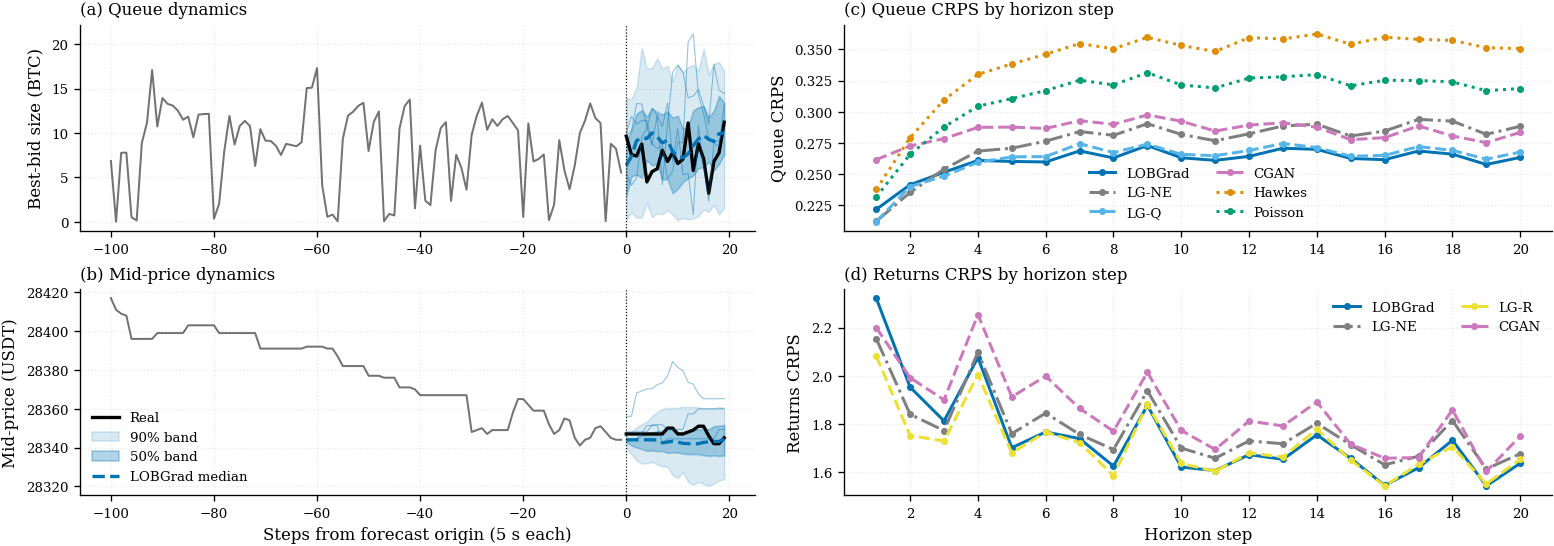

In [18]:
from lobgrad.eval.evaluate import crps_snapshot                                                                                                                               

                                                                                                                                                                                
def _crps_by_step(real_fut, gen_feats):
    W, H = real_fut.shape[:2]                                                                                                                                                   
    out = np.zeros(H)
    for t in range(H):
        out[t] = np.mean([
            crps_snapshot(real_fut[w, t], gen_feats[w, :, t])                                                                                                                   
            for w in range(W)
        ])                                                                                                                                                                      
    return out  

                                                                                                                                                                                
def _crps_by_step_returns(real_mid, gen_mid, last_ctx_anchor):
    """Per-step CRPS on Δmid (returns).                                                                                                                                         
                
    real_mid        : (W, H)
    gen_mid         : (W, N_PATHS, H)
    last_ctx_anchor : (W,)  — last anchor of each window's context, i.e. test_ctx_a[:, -1]                                                                                      
    """
    W, H = real_mid.shape                                                                                                                                                       
    # Real returns: Δmid_t = mid_t − mid_{t-1}, with mid_{-1} = last context anchor.                                                                                            
    real_prev = np.concatenate([last_ctx_anchor[:, None], real_mid[:, :-1]], axis=1)                                                                                            
    real_ret  = real_mid - real_prev                                       # (W, H)                                                                                             
    # Generated returns: same convention, broadcast the anchor across paths.                                                                                                    
    anchor_b = np.broadcast_to(last_ctx_anchor[:, None, None],
                                (W, gen_mid.shape[1], 1))                                                                                                                        
    gen_prev = np.concatenate([anchor_b, gen_mid[:, :, :-1]], axis=2)
    gen_ret  = gen_mid - gen_prev                                          # (W, N, H)                                                                                          
                
    out = np.zeros(H)                                                                                                                                                           
    for t in range(H):
        out[t] = np.mean([
            crps_snapshot(np.atleast_1d(real_ret[w, t]),                                                                                                                        
                        gen_ret[w, :, t:t + 1])
            for w in range(W)                                                                                                                                                   
        ])                                                                                                                                                                      
    return out
                                                                                                                                                                                
                
if TG_LABEL not in gen_mid_long:
    print(f"⚠  {TG_LABEL} did not produce price paths — skipping side-by-side figure.")
else:                                                                                                                                                                           
    W_IDX  = 0
    N_PEEK = 3                                                                                                                                                                  
    fan_rng  = np.random.default_rng(0)
    peek_idx = fan_rng.choice(N_PATHS, size=N_PEEK, replace=False)
                                                                                                                                                                                
    t_ctx = np.arange(-CONTEXT_LEN, 0)
    t_fut = np.arange(HORIZON)                                                                                                                                                  
    TG_C  = PALETTE[TG_LABEL]                                                                                                                                                   
    RL_C  = PALETTE["Real"]
                                                                                                                                                                                
    ctx_bid  = np.abs(normalizer.inverse_transform(test_ctx_q[W_IDX])[:, 0])                                                                                                    
    real_bid = np.abs(normalizer.inverse_transform(test_fut_q[W_IDX])[:, 0])
    gen_bid  = np.abs(normalizer.inverse_transform(                                                                                                                             
        gen_long[TG_LABEL][W_IDX].reshape(N_PATHS, HORIZON, 2 * K))[:, :, 0])
    gen_mid_w = gen_mid_long[TG_LABEL][W_IDX]                                                                                                                                   
                                                                                                                                                                                
    def _bands(x):                                                                                                                                                              
        return np.quantile(x, [0.05, 0.25, 0.50, 0.75, 0.95], axis=0)                                                                                                           
                
    fig = plt.figure(figsize=(13.0, 4.6), constrained_layout=True)                                                                                                              
    gs  = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.05])
                                                                                                                                                                                
    # ── Left col, top: queue dynamics ──
    ax_q = fig.add_subplot(gs[0, 0])                                                                                                                                            
    q05, q25, q50, q75, q95 = _bands(gen_bid)
    ax_q.plot(t_ctx, ctx_bid,  color=RL_C, lw=1.2, alpha=0.55)                                                                                                                  
    ax_q.plot(t_fut, real_bid, color=RL_C, lw=2.0, label="Real")
    ax_q.fill_between(t_fut, q05, q95, color=TG_C, alpha=0.15, label="90% band")                                                                                                
    ax_q.fill_between(t_fut, q25, q75, color=TG_C, alpha=0.30, label="50% band")                                                                                                
    ax_q.plot(t_fut, q50, color=TG_C, lw=2.0, ls="--", label=f"{TG_LABEL} median")                                                                                              
    for p in peek_idx:                                                                                                                                                          
        ax_q.plot(t_fut, gen_bid[p], color=TG_C, lw=0.6, alpha=0.45)
    ax_q.axvline(0, color="k", lw=0.7, ls=":")                                                                                                                                  
    ax_q.set_ylabel("Best-bid size (BTC)")                                                                                                                                                                                                                                                          
    ax_q.set_title("(a) Queue dynamics", loc="left", fontsize=10)                                                                                                               
                                                                                                                                                                                
    # ── Left col, bottom: mid-price dynamics ──
    ax_m = fig.add_subplot(gs[1, 0], sharex=ax_q)                                                                                                                               
    q05, q25, q50, q75, q95 = _bands(gen_mid_w)                                                                                                                                 
    ax_m.plot(t_ctx, test_ctx_a[W_IDX], color=RL_C, lw=1.2, alpha=0.55)
    ax_m.plot(t_fut, test_fut_a[W_IDX], color=RL_C, lw=2.0, label="Real")                                                                                                       
    ax_m.fill_between(t_fut, q05, q95, color=TG_C, alpha=0.15, label="90% band")                                                                                                
    ax_m.fill_between(t_fut, q25, q75, color=TG_C, alpha=0.30, label="50% band")                                                                                                
    ax_m.plot(t_fut, q50, color=TG_C, lw=2.0, ls="--", label=f"{TG_LABEL} median")                                                                                              
    for p in peek_idx:                                                                                                                                                          
        ax_m.plot(t_fut, gen_mid_w[p], color=TG_C, lw=0.6, alpha=0.45)                                                                                                          
    ax_m.axvline(0, color="k", lw=0.7, ls=":")                                                                                                                                  
    ax_m.set_xlabel("Steps from forecast origin (5 s each)")
    ax_m.set_ylabel("Mid-price (USDT)")                                                                                                                                         
    ax_m.legend(frameon=False, loc="best", fontsize=8)
    ax_m.set_title("(b) Mid-price dynamics", loc="left", fontsize=10)                                                                                                           
                
    # ── Right col, top: queue CRPS by horizon step ──                                                                                                                          
    ax_cq = fig.add_subplot(gs[0, 1])
    steps = np.arange(1, HORIZON + 1)                                                                                                                                           
    for name in MODELS:
        if name not in gen_long:
            continue                                                                                                                                                            
        scores = _crps_by_step(test_fut_q, gen_long[name])
        ax_cq.plot(steps, scores,                                                                                                                                               
                    color=PALETTE[name], ls=LINESTYLES.get(name, "-"),
                    lw=1.8, marker="o", ms=3.2, label=name)                                                                                                                      
    ax_cq.set_ylabel("Queue CRPS")
    ax_cq.set_xticks(np.arange(2, HORIZON + 1, 2))                                                                                                                              
    ax_cq.legend(frameon=False, ncol=2, fontsize=8)
    ax_cq.set_title("(c) Queue CRPS by horizon step", loc="left", fontsize=10)                                                                                                  
                
    # ── Right col, bottom: returns CRPS by horizon step ──                                                                                                                     
    ax_cp = fig.add_subplot(gs[1, 1], sharex=ax_cq)
    last_anchor = test_ctx_a[:, -1]                                                                                                                                             
    for name in MODELS:                                                                                                                                                         
        if name not in gen_mid_long:
            continue                                                                                                                                                            
        scores = _crps_by_step_returns(test_fut_a, gen_mid_long[name], last_anchor)
        ax_cp.plot(steps, scores,                                                                                                                                               
                    color=PALETTE[name], ls=LINESTYLES.get(name, "-"),
                    lw=1.8, marker="o", ms=3.2, label=name)                                                                                                                      
    ax_cp.set_xlabel("Horizon step")                                                                                                                                            
    ax_cp.set_ylabel("Returns CRPS")
    ax_cp.set_xticks(np.arange(2, HORIZON + 1, 2))                                                                                                                              
    ax_cp.legend(frameon=False, ncol=2, fontsize=8)                                                                                                                             
    ax_cp.set_title("(d) Returns CRPS by horizon step", loc="left", fontsize=10)
                                                                                                                                                                                
    _savefig(fig, "fig_trajectory_fan_crps.pdf", "main")

### Figure 2 — Price stylized facts

Three-panel: return distribution, ACF of returns (efficient-market check),
ACF of |returns| (volatility-clustering check). Only the joint model can
produce these — comparison is JointTimeGrad vs. Real.

saved figures/main/fig_price_stylized.pdf


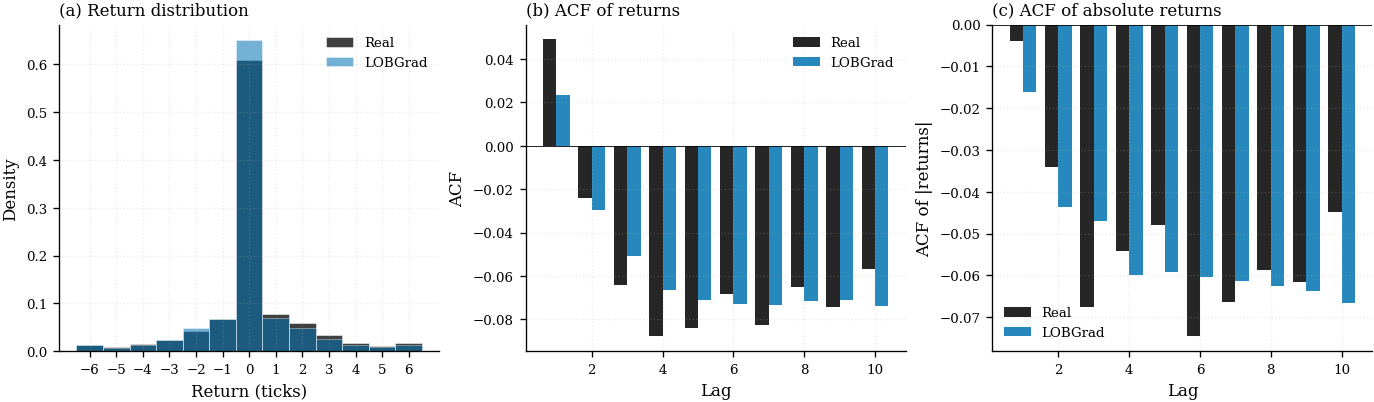

In [19]:
def _mean_acf(series_2d, max_lag=10):
    acfs = []
    for row in series_2d:
        row = row - row.mean()
        var = np.var(row) + 1e-10
        acfs.append([np.mean(row[:len(row)-l] * row[l:]) / var
                     for l in range(1, max_lag + 1)])
    return np.mean(acfs, axis=0)


if TG_LABEL not in gen_mid_long:
    print(f"⚠  {TG_LABEL} did not produce price paths — skipping stylized facts.")
else:
    mid_gen      = gen_mid_long[TG_LABEL]
    real_mid_fut = test_fut_a
    TG_C, RL_C   = PALETTE[TG_LABEL], PALETTE["Real"]
    lags         = np.arange(1, 11)
    w            = 0.38
    TICK         = PRICE_LEVEL

    real_ticks   = np.diff(real_mid_fut, axis=1).flatten() / TICK
    gen_ticks    = np.diff(mid_gen,      axis=2).flatten() / TICK
    # Pool across (window, path) for the ACF panels — match how the
    # real side pools across windows.
    gen_ret_all  = np.diff(mid_gen, axis=2).reshape(-1, HORIZON - 1)

    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4), constrained_layout=True)

    # ── Panel a: return distribution
    ax = axes[0]
    tick_range = 6
    bins = np.arange(-tick_range - 0.5, tick_range + 1.5, 1.0)
    ax.hist(np.clip(real_ticks, -tick_range, tick_range), bins=bins, density=True,
            alpha=0.75, color=RL_C, label="Real", edgecolor="white", linewidth=0.4)
    ax.hist(np.clip(gen_ticks, -tick_range, tick_range), bins=bins, density=True,
            alpha=0.55, color=TG_C, label=TG_LABEL, edgecolor="white", linewidth=0.4)
    ax.set_xlabel("Return (ticks)"); ax.set_ylabel("Density")
    ax.set_title("(a) Return distribution", loc="left", fontsize=10)
    ax.set_xticks(range(-tick_range, tick_range + 1))
    ax.legend(frameon=False)

    # ── Panel b: ACF(returns)
    ax = axes[1]
    real_acf_r = _mean_acf(np.diff(real_mid_fut, axis=1))
    gen_acf_r  = _mean_acf(gen_ret_all)
    ax.bar(lags - w/2, real_acf_r, w, color=RL_C, alpha=0.85, label="Real")
    ax.bar(lags + w/2, gen_acf_r,  w, color=TG_C, alpha=0.85, label=TG_LABEL)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("Lag"); ax.set_ylabel("ACF")
    ax.set_title("(b) ACF of returns", loc="left", fontsize=10)
    ax.legend(frameon=False)

    # ── Panel c: ACF(|returns|)
    ax = axes[2]
    real_acf_abs = _mean_acf(np.abs(np.diff(real_mid_fut, axis=1)))
    gen_acf_abs  = _mean_acf(np.abs(gen_ret_all))
    ax.bar(lags - w/2, real_acf_abs, w, color=RL_C, alpha=0.85, label="Real")
    ax.bar(lags + w/2, gen_acf_abs,  w, color=TG_C, alpha=0.85, label=TG_LABEL)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("Lag"); ax.set_ylabel("ACF of |returns|")
    ax.set_title("(c) ACF of absolute returns", loc="left", fontsize=10)
    ax.legend(frameon=False)

    _savefig(fig, "fig_price_stylized.pdf", "main")


## §A  Appendix


### Figure A1 — 2×5 queue marginal distributions

Per-level KDE of physical queue size, all five models overlaid on the real
distribution. Top row = bid sides L1…L5; bottom row = ask sides L1…L5.

/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


saved figures/appendix/fig_queue_marginals.pdf


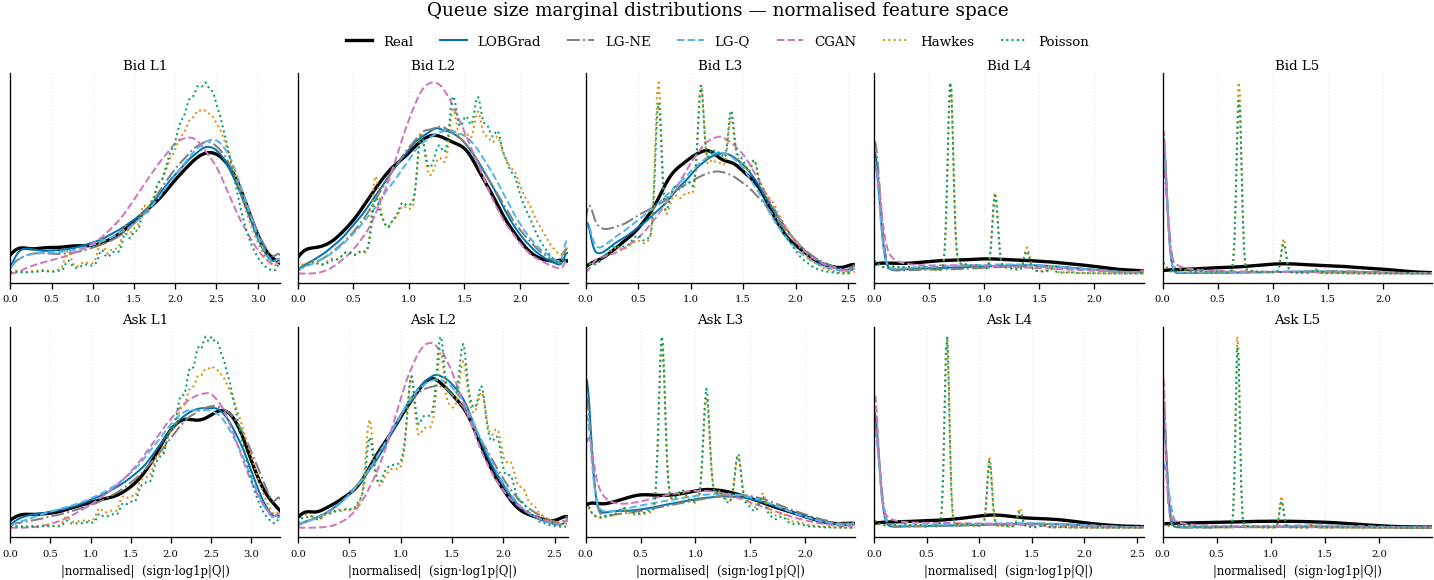

In [20]:
# ── Marginal distributions in NORMALISED feature space ──────────────────
# i.e. sign(Q) * log1p(|Q|) under the signed convention. Bids are ≤ 0,
# asks are ≥ 0. We take |·| so each cell's KDE is a density of magnitudes.
real_flat = test_fut_q.reshape(-1, 2 * K)
real_norm = np.abs(real_flat)
gen_norm  = {n: np.abs(gen_long[n].reshape(-1, 2*K)) for n in MODELS if n in gen_long}

fig, axes = plt.subplots(2, K, figsize=(2.4*K, 4.4),
                         sharey=False, constrained_layout=True)

for l in range(K):
    for row, col_idx in enumerate([l, K + l]):
        ax     = axes[row, l]
        vals_r = real_norm[:, col_idx]
        pos_r  = vals_r[vals_r > 0]
        if len(pos_r) < 10:
            ax.set_visible(False); continue
        clip_hi = max(float(np.percentile(pos_r, 99)), 1e-6)
        xg      = np.linspace(0, clip_hi, 200)
        try:
            ax.plot(xg, gaussian_kde(np.clip(pos_r, 0, clip_hi))(xg),
                    color=PALETTE["Real"], lw=2.0,
                    label="Real" if (row == 0 and l == 0) else "_nolegend_")
        except Exception:
            pass
        for name in MODELS:
            if name not in gen_norm:
                continue
            pos_g = gen_norm[name][:, col_idx]
            pos_g = pos_g[pos_g > 0]
            if len(pos_g) < 10: continue
            try:
                ax.plot(xg, gaussian_kde(np.clip(pos_g, 0, clip_hi))(xg),
                        color=PALETTE[name], ls=LINESTYLES.get(name, "--"), lw=1.2,
                        label=name if (row == 0 and l == 0) else "_nolegend_")
            except Exception:
                pass
        ax.set_xlim(0, clip_hi)
        ax.set_title(f"{'Bid' if row == 0 else 'Ask'} L{l+1}", fontsize=8, pad=2)
        ax.set_yticks([])
        if row == 1:
            ax.set_xlabel("|normalised|  (sign·log1p|Q|)", fontsize=7)
        ax.tick_params(axis="x", labelsize=6)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(handles),
           fontsize=8, bbox_to_anchor=(0.5, 1.06), frameon=False)
fig.suptitle("Queue size marginal distributions — normalised feature space",
             fontsize=11, y=1.10)
_savefig(fig, "fig_queue_marginals.pdf", "appendix")


### Figure A2 — Cross-level queue correlation

**Top row:** raw Pearson correlation across the 2K queue levels for Real and
each model. Real shows a block structure (bid block, ask block, weak
cross-side); classical baselines miss it.

**Bottom row:** per-model deviation from real, `(Model − Real)` clipped to
±0.5, with RMSE annotated. Smaller / paler is better. Highlights *where*
each model gets the correlation structure wrong, not just *that* it does.

saved figures/appendix/fig_corr_heatmap.pdf


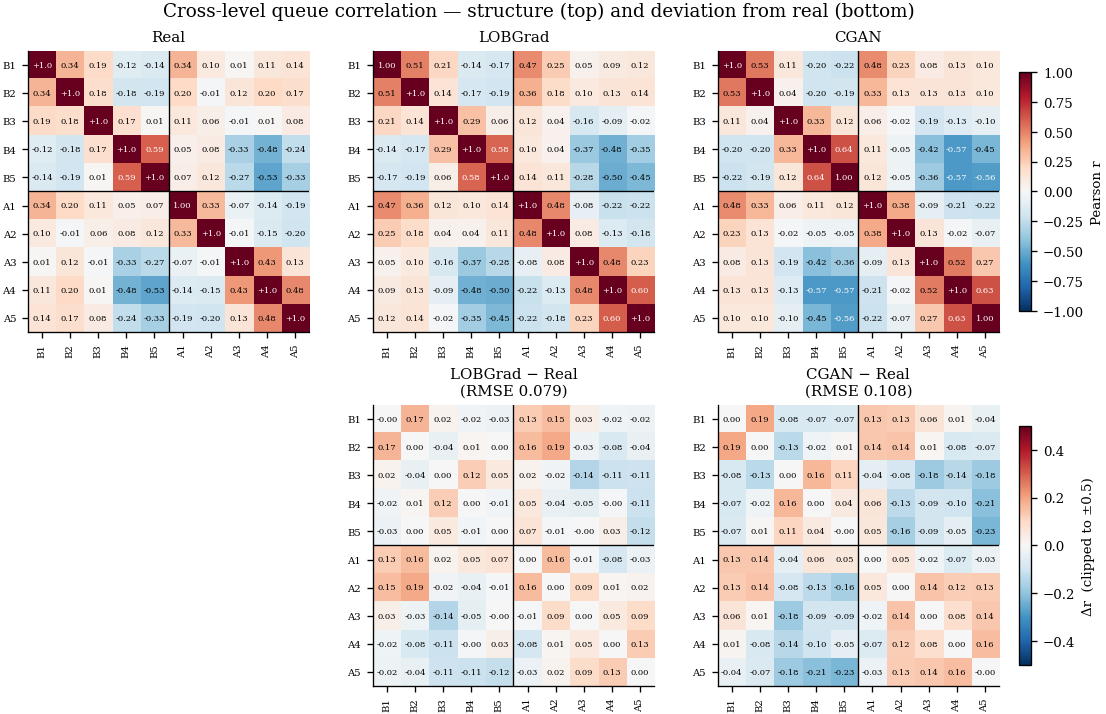

In [21]:
def _corr_matrix(features_2d):
    n = features_2d.shape[0]
    if n > 50_000:
        idx = np.random.default_rng(1).choice(n, 50_000, replace=False)
        features_2d = features_2d[idx]
    return np.corrcoef(features_2d.T)


def _annotate(ax, M, vmax_for_color):
    """Print each matrix value in its cell. White text over saturated cells."""
    n = M.shape[0]
    thresh = 0.55 * vmax_for_color   # text colour switch
    for i in range(n):
        for j in range(n):
            v = M[i, j]
            ax.text(j, i, f"{v:+.2f}".lstrip("+") if abs(v) < 1 else f"{v:+.1f}",
                    ha="center", va="center",
                    fontsize=5,
                    color=("white" if abs(v) > thresh else "black"))


# Show: Real, JointTimeGrad, TimeGrad-Q (if avail), CGAN (if avail), Hawkes
preferred  = [TG_LABEL, "CGAN"]
gen_names  = [n for n in preferred if n in MODELS]
plot_names = ["Real"] + gen_names

corr_feats = {"Real": real_flat,
              **{n: gen_long[n].reshape(-1, 2*K) for n in MODELS if n in gen_long}}

# Pre-compute correlation matrices
C_all = {n: _corr_matrix(corr_feats[n]) for n in plot_names}

level_labels = [f"B{i+1}" for i in range(K)] + [f"A{i+1}" for i in range(K)]
n_cols = len(plot_names)
DIFF_CLIP = 0.5

fig, axes = plt.subplots(
    2, n_cols,
    figsize=(2.9*n_cols + 0.8, 6.0),
    constrained_layout=True,
)

# ─── Row 0: raw correlation matrices ────────────────────────────────
im_corr = None
for col, name in enumerate(plot_names):
    ax = axes[0, col]
    im_corr = ax.imshow(C_all[name], vmin=-1, vmax=1, cmap="RdBu_r", aspect="equal")
    _annotate(ax, C_all[name], vmax_for_color=1.0)
    ax.set_title(name, fontsize=9)
    ax.set_xticks(range(2*K)); ax.set_yticks(range(2*K))
    ax.set_xticklabels(level_labels, fontsize=6, rotation=90)
    ax.set_yticklabels(level_labels, fontsize=6)
    ax.axvline(K - 0.5, color="k", lw=0.8)
    ax.axhline(K - 0.5, color="k", lw=0.8)
    ax.grid(False)

# ─── Row 1: difference matrices (Model − Real) ──────────────────────
axes[1, 0].set_visible(False)
im_diff = None
for col, name in enumerate(plot_names):
    if col == 0:
        continue
    ax = axes[1, col]
    diff = C_all[name] - C_all["Real"]
    im_diff = ax.imshow(
        diff, vmin=-DIFF_CLIP, vmax=DIFF_CLIP, cmap="RdBu_r", aspect="equal"
    )
    _annotate(ax, diff, vmax_for_color=DIFF_CLIP)
    rmse = float(np.sqrt(np.mean(diff ** 2)))
    ax.set_title(f"{name} − Real\n(RMSE {rmse:.3f})", fontsize=9)
    ax.set_xticks(range(2*K)); ax.set_yticks(range(2*K))
    ax.set_xticklabels(level_labels, fontsize=6, rotation=90)
    ax.set_yticklabels(level_labels, fontsize=6)
    ax.axvline(K - 0.5, color="k", lw=0.8)
    ax.axhline(K - 0.5, color="k", lw=0.8)
    ax.grid(False)

# Two colorbars
if im_corr is not None:
    cb1 = fig.colorbar(im_corr, ax=axes[0, :].tolist(),
                       fraction=0.025, pad=0.02, shrink=0.85)
    cb1.set_label("Pearson r", fontsize=8)
if im_diff is not None:
    cb2 = fig.colorbar(im_diff, ax=axes[1, :].tolist(),
                       fraction=0.025, pad=0.02, shrink=0.85)
    cb2.set_label(f"Δr  (clipped to ±{DIFF_CLIP})", fontsize=8)

fig.suptitle("Cross-level queue correlation — structure (top) and deviation from real (bottom)",
             fontsize=11)
_savefig(fig, "fig_corr_heatmap.pdf", "appendix")


### Figure A3 — Depth profile + L1 KDE

Mean queue size by depth level (bid + ask), plus best-bid and best-ask
distributions. Sanity check that the distributions of the generated queues
match the real LOB shape.

/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/opt/miniconda3/envs/FinM/lib/python3.13/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


saved figures/appendix/fig_queue_dist.pdf


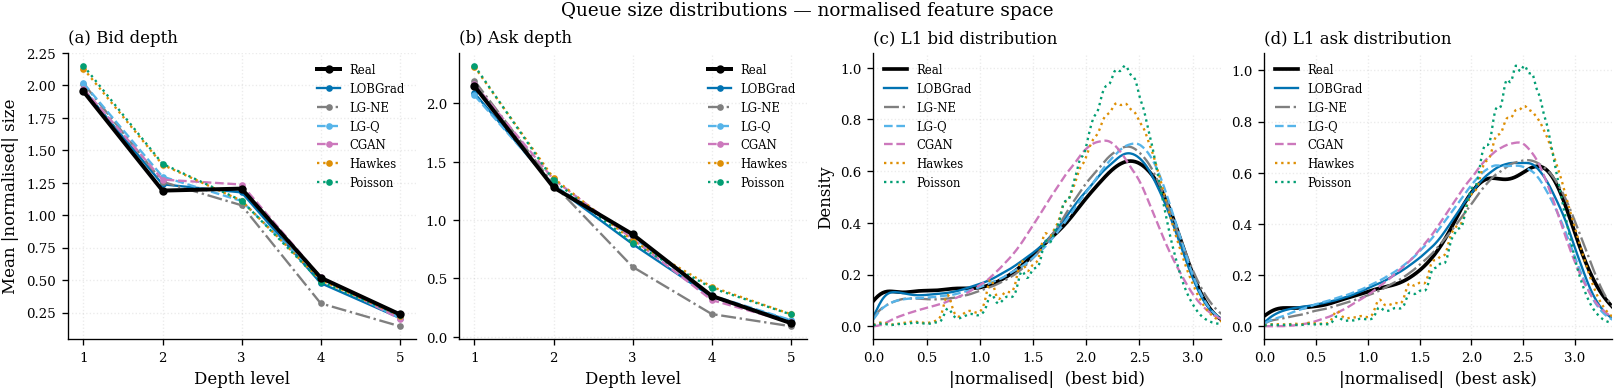

In [22]:
# ── Depth profile + L1 KDE in NORMALISED feature space ───────────────────
# Skip normalizer.inverse_transform; operate directly on signed log-volume features.

def _mean_depth_profile_norm(features_2d, k):
    n = features_2d.shape[0]
    if n > 30_000:
        idx = np.random.default_rng(0).choice(n, 30_000, replace=False)
        features_2d = features_2d[idx]
    return (np.abs(features_2d[:, :k]).mean(0),
            np.abs(features_2d[:, k:]).mean(0))


def _l1_kde_norm(features_2d, level_idx, x_hi=None):
    raw = np.abs(features_2d[:, level_idx])
    raw = raw[raw > 0]
    if x_hi is None:
        x_hi = np.percentile(raw, 99)
    mask = raw < x_hi * 1.5
    if mask.sum() < 10:
        return None, x_hi
    return gaussian_kde(raw[mask]), x_hi


LEVELS_X = np.arange(1, K + 1)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.3), constrained_layout=True)

bid_r, ask_r = _mean_depth_profile_norm(real_flat, K)

# (a) Bid depth — normalised
ax = axes[0]
ax.plot(LEVELS_X, bid_r, color=PALETTE["Real"], lw=2.4, marker="o",
        ms=4, label="Real", zorder=5)
for name in MODELS:
    if name not in gen_long:
        continue
    gf = gen_long[name].reshape(-1, 2 * K)
    b, _ = _mean_depth_profile_norm(gf, K)
    ax.plot(LEVELS_X, b, color=PALETTE[name], ls=LINESTYLES.get(name, "--"),
            lw=1.4, marker="o", ms=3, label=name)
ax.set_xticks(LEVELS_X)
ax.set_xlabel("Depth level"); ax.set_ylabel("Mean |normalised| size")
ax.set_title("(a) Bid depth", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=7)

# (b) Ask depth — normalised
ax = axes[1]
ax.plot(LEVELS_X, ask_r, color=PALETTE["Real"], lw=2.4, marker="o",
        ms=4, label="Real", zorder=5)
for name in MODELS:
    if name not in gen_long:
        continue
    gf = gen_long[name].reshape(-1, 2 * K)
    _, a = _mean_depth_profile_norm(gf, K)
    ax.plot(LEVELS_X, a, color=PALETTE[name], ls=LINESTYLES.get(name, "--"),
            lw=1.4, marker="o", ms=3, label=name)
ax.set_xticks(LEVELS_X)
ax.set_xlabel("Depth level")
ax.set_title("(b) Ask depth", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=7)

# (c) Best-bid KDE — normalised
ax = axes[2]
kde_r, x_hi_b = _l1_kde_norm(real_flat, 0)
xg = np.linspace(0, x_hi_b, 300)
if kde_r is not None:
    ax.plot(xg, kde_r(xg), color=PALETTE["Real"], lw=2.2, label="Real")
for name in MODELS:
    if name not in gen_long:
        continue
    gf = gen_long[name].reshape(-1, 2 * K)
    kde_g, _ = _l1_kde_norm(gf, 0, x_hi=x_hi_b)
    if kde_g is not None:
        ax.plot(xg, kde_g(xg), color=PALETTE[name],
                ls=LINESTYLES.get(name, "--"), lw=1.4, label=name)
ax.set_xlim(0, x_hi_b)
ax.set_xlabel("|normalised|  (best bid)"); ax.set_ylabel("Density")
ax.set_title("(c) L1 bid distribution", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=7)

# (d) Best-ask KDE — normalised
ax = axes[3]
kde_r, x_hi_a = _l1_kde_norm(real_flat, K)
x_hi_a = max(float(x_hi_a), 1e-8)
xg = np.linspace(0, x_hi_a, 300)
if kde_r is not None:
    ax.plot(xg, kde_r(xg), color=PALETTE["Real"], lw=2.2, label="Real")
for name in MODELS:
    if name not in gen_long:
        continue
    gf = gen_long[name].reshape(-1, 2 * K)
    kde_g, _ = _l1_kde_norm(gf, K, x_hi=x_hi_a)
    if kde_g is not None:
        ax.plot(xg, kde_g(xg), color=PALETTE[name],
                ls=LINESTYLES.get(name, "--"), lw=1.4, label=name)
ax.set_xlim(0, x_hi_a)
ax.set_xlabel("|normalised|  (best ask)")
ax.set_title("(d) L1 ask distribution", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=7)

fig.suptitle("Queue size distributions — normalised feature space", fontsize=11)
_savefig(fig, "fig_queue_dist.pdf", "appendix")
